# Retail Sales and Customer Value

**Author:** Mohammed Adeen Shaik

## Research question

How do revenue, basket value and customer contribution vary across this historical retail sample?

## Data and evidence

UCI Online Retail transactions from December 2010 to December 2011.

Fresh pipeline execution on 11 October 2026. The **13 monthly reporting buckets** contain aggregate net revenue of **10,666,684.54 GBP**. The customer RFM table contains **4,338 identified customers**. These totals follow the cleaning and return rules in src/build_model.py. The first and last buckets are incomplete calendar months and should not be used as comparable growth endpoints.

| Measure | Value |
|---|---:|
| monthly buckets | 13 |
| net revenue GBP | 10666684.5440 |
| identified RFM customers | 4338 |



## Reading guide

Read each explanation before its code cell. Run from top to bottom in the documented working directory. A saved chart is an output snapshot, not proof that this notebook was rerun today. The final section collects findings and visual evidence.

## Method

Validated transaction rows are aggregated to monthly KPIs, products and countries. RFM groups summarize how recently and frequently customers purchased and how much they spent.

## Interpretation limits

Partial months distort month-to-month comparisons. RFM labels are descriptive rules, not experimentally validated marketing segments. Returns and unidentified customers require explicit treatment.

# Retail Sales and Customer Value — Key Visuals

Run the data pipeline before this notebook. These visuals support executive trend, customer-value, and product-mix review.

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})


### Guide to code step 2

**Load the source table.** A DataFrame is a spreadsheet-like table in memory. The path must point to the documented input file; loading a file does not validate its contents.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/processed")
monthly = pd.read_csv(DATA / "monthly_kpis.csv")
rfm = pd.read_csv(DATA / "customer_rfm.csv")
products = pd.read_csv(DATA / "product_performance.csv")


### Guide to code step 3

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

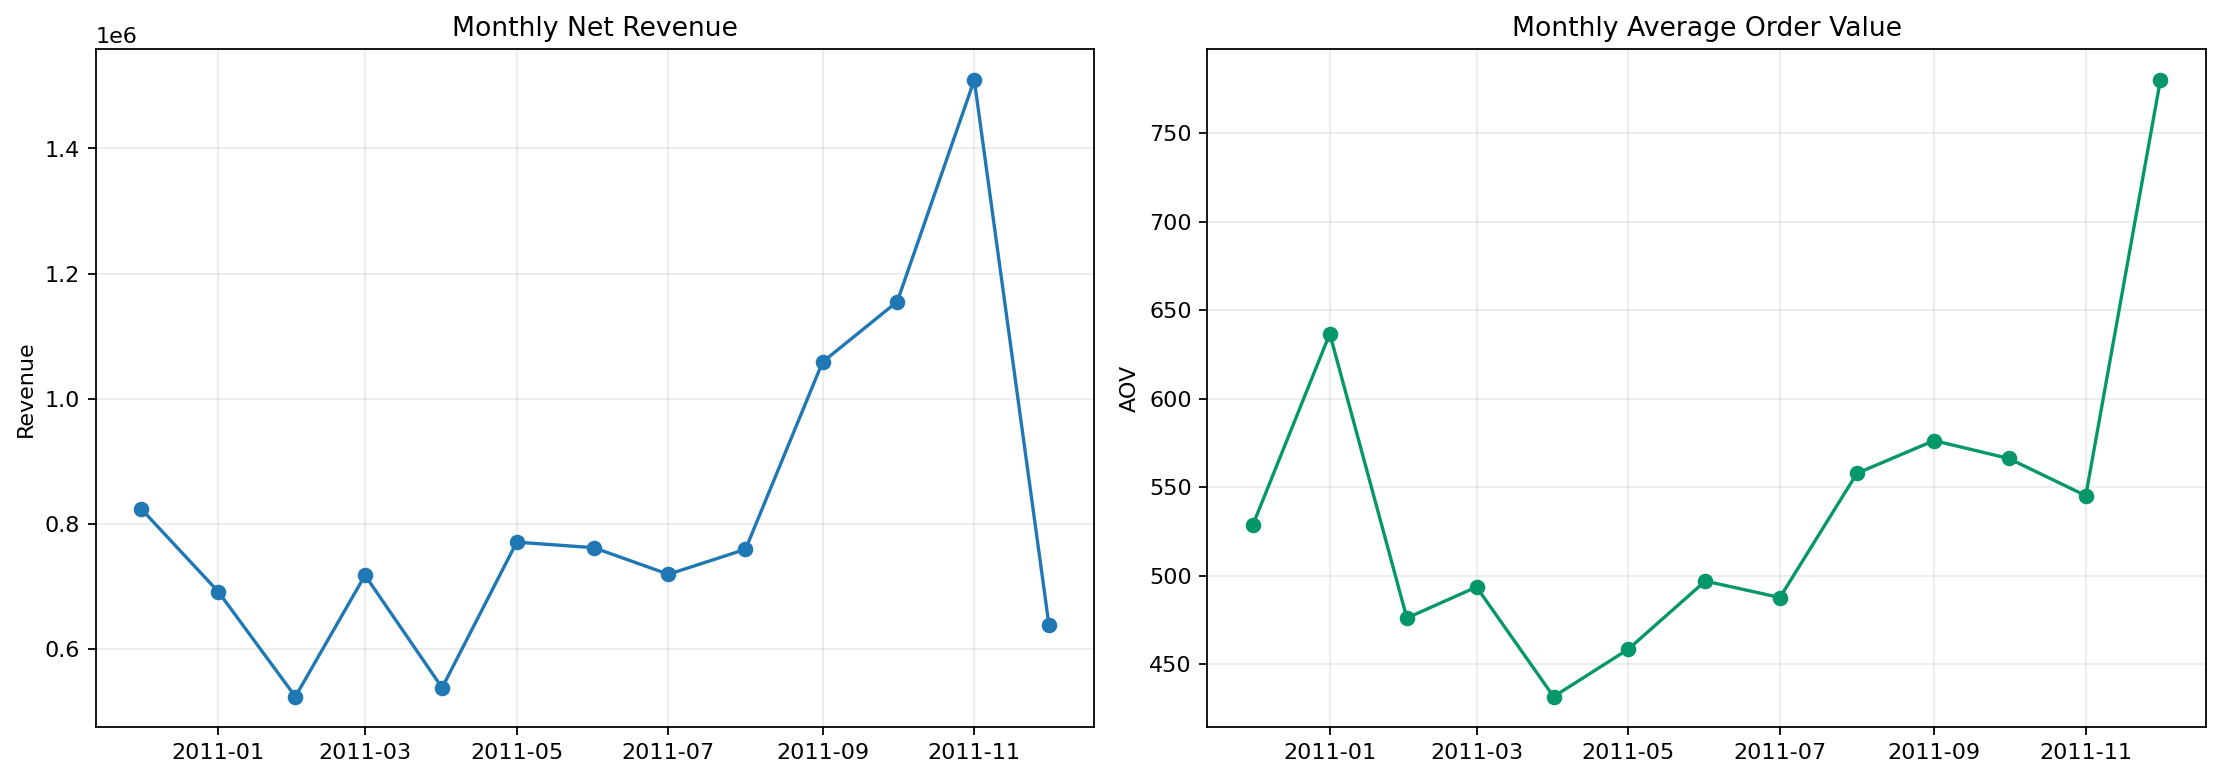

In [2]:
monthly["InvoiceMonth"] = pd.to_datetime(monthly["InvoiceMonth"])
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(monthly["InvoiceMonth"], monthly["NetRevenue"], marker="o")
axes[0].set(title="Monthly Net Revenue", ylabel="Revenue")
axes[1].plot(monthly["InvoiceMonth"], monthly["AverageOrderValue"], marker="o", color="#059669")
axes[1].set(title="Monthly Average Order Value", ylabel="AOV")
for axis in axes:
    axis.grid(alpha=0.25)
figure.tight_layout()


### Guide to code step 4

**Summarize observations.** Grouping collects rows with the same label. Counts and sums produce totals; a mean of a binary 0/1 indicator gives a rate. Always identify the denominator and keep missing categories visible.

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

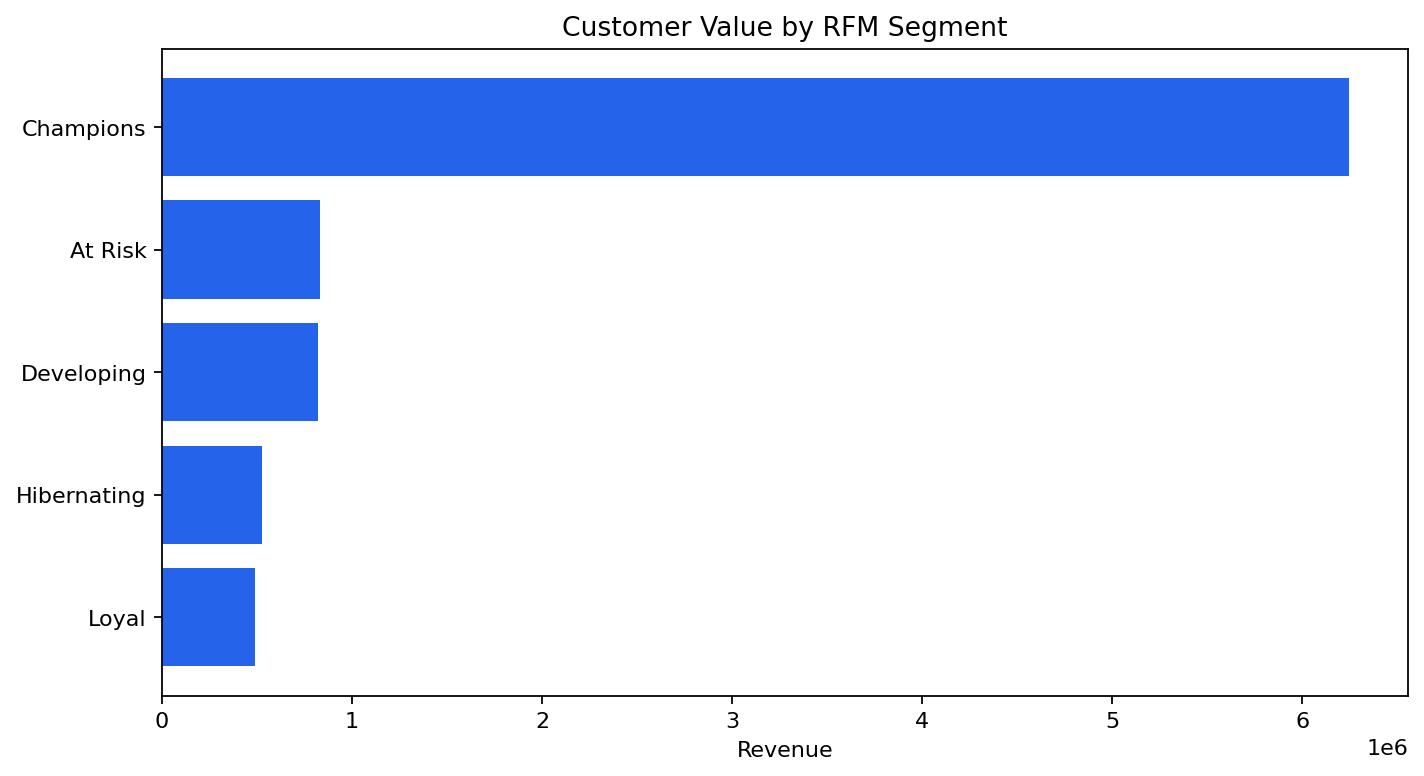

In [3]:
segment = rfm.groupby("Segment", as_index=False).agg(
    Customers=("CustomerID", "nunique"),
    Revenue=("MonetaryValue", "sum"),
).sort_values("Revenue")
figure, axis = plt.subplots(figsize=(9, 5))
axis.barh(segment["Segment"], segment["Revenue"], color="#2563EB")
axis.set(title="Customer Value by RFM Segment", xlabel="Revenue")
figure.tight_layout()


### Guide to code step 5

**Read the chart.** The axis labels identify units and the grouping defines what is compared. A visual association does not establish cause. Rate charts need denominators; truncated axes can exaggerate small differences.

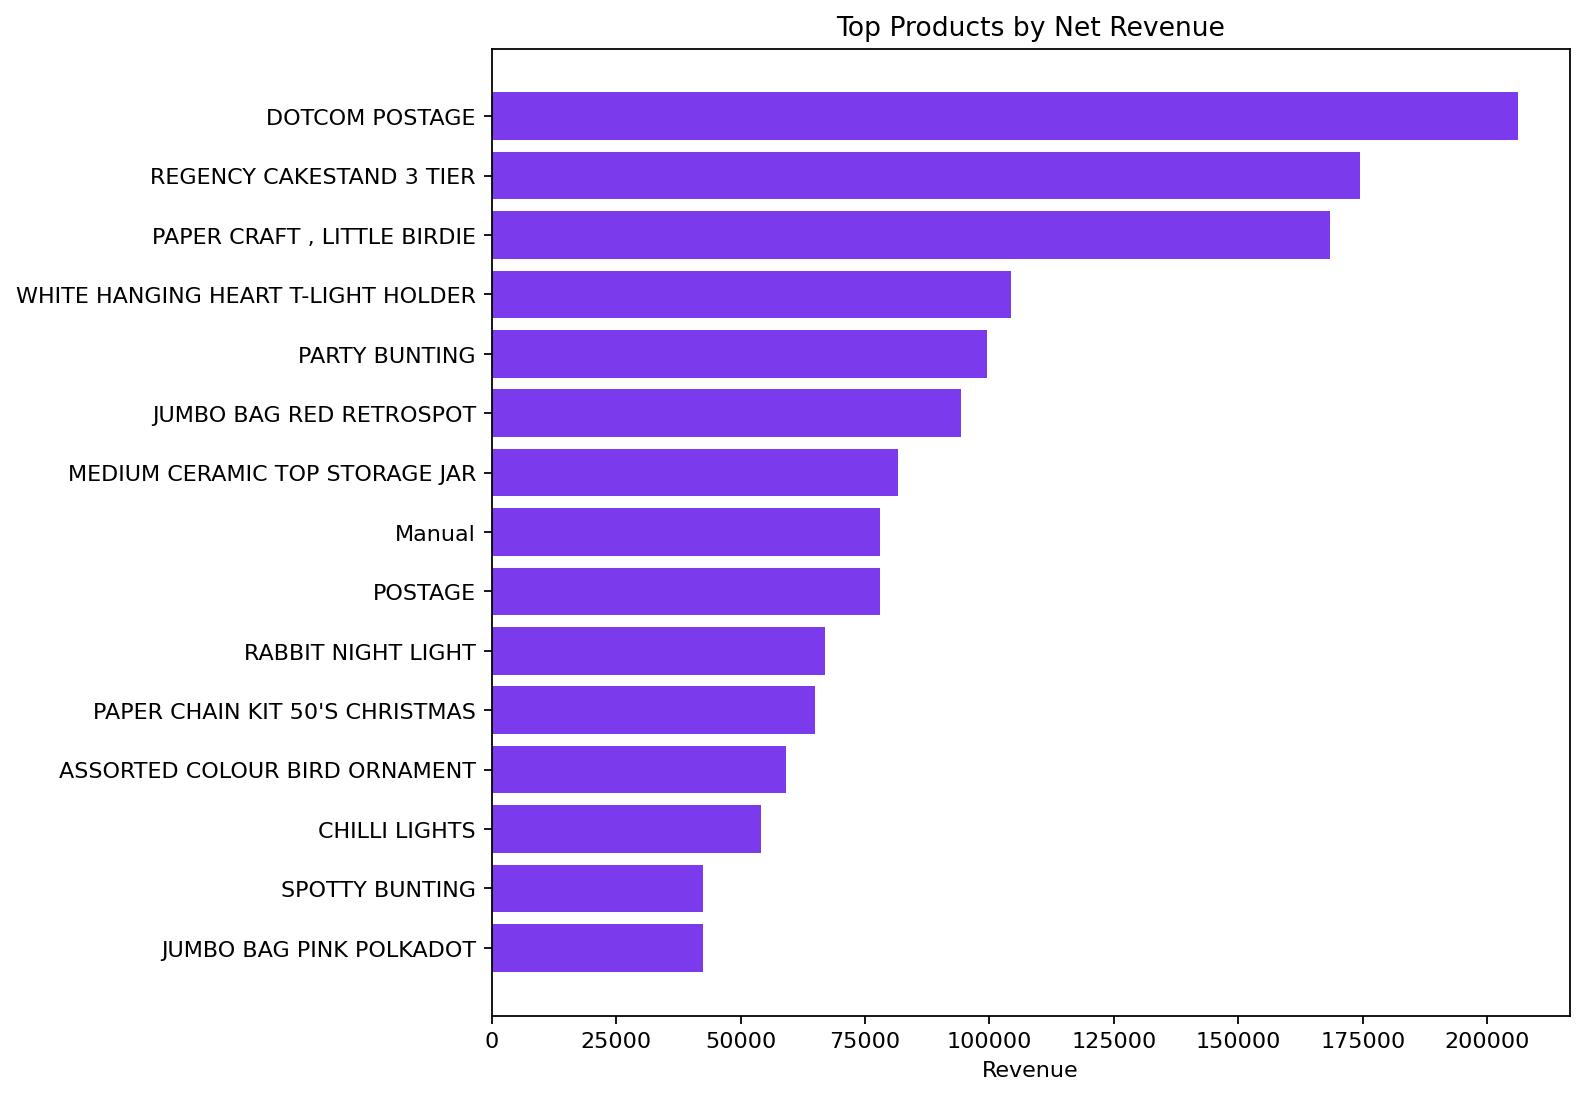

In [4]:
top_products = products.head(15).sort_values("NetRevenue")
figure, axis = plt.subplots(figsize=(10, 7))
axis.barh(top_products["Description"], top_products["NetRevenue"], color="#7C3AED")
axis.set(title="Top Products by Net Revenue", xlabel="Revenue")
figure.tight_layout()


## Findings and final visual results

Fresh pipeline execution on 11 October 2026. The **13 monthly reporting buckets** contain aggregate net revenue of **10,666,684.54 GBP**. The customer RFM table contains **4,338 identified customers**. These totals follow the cleaning and return rules in src/build_model.py. The first and last buckets are incomplete calendar months and should not be used as comparable growth endpoints.

| Measure | Value |
|---|---:|
| monthly buckets | 13 |
| net revenue GBP | 10666684.5440 |
| identified RFM customers | 4338 |



Partial months distort month-to-month comparisons. RFM labels are descriptive rules, not experimentally validated marketing segments. Returns and unidentified customers require explicit treatment.

The following figures are copied from saved notebook outputs or the documented evaluation artifacts. Their source and evidence status are given in the research report.


**Figure from key_visuals.ipynb, original code cell 3**

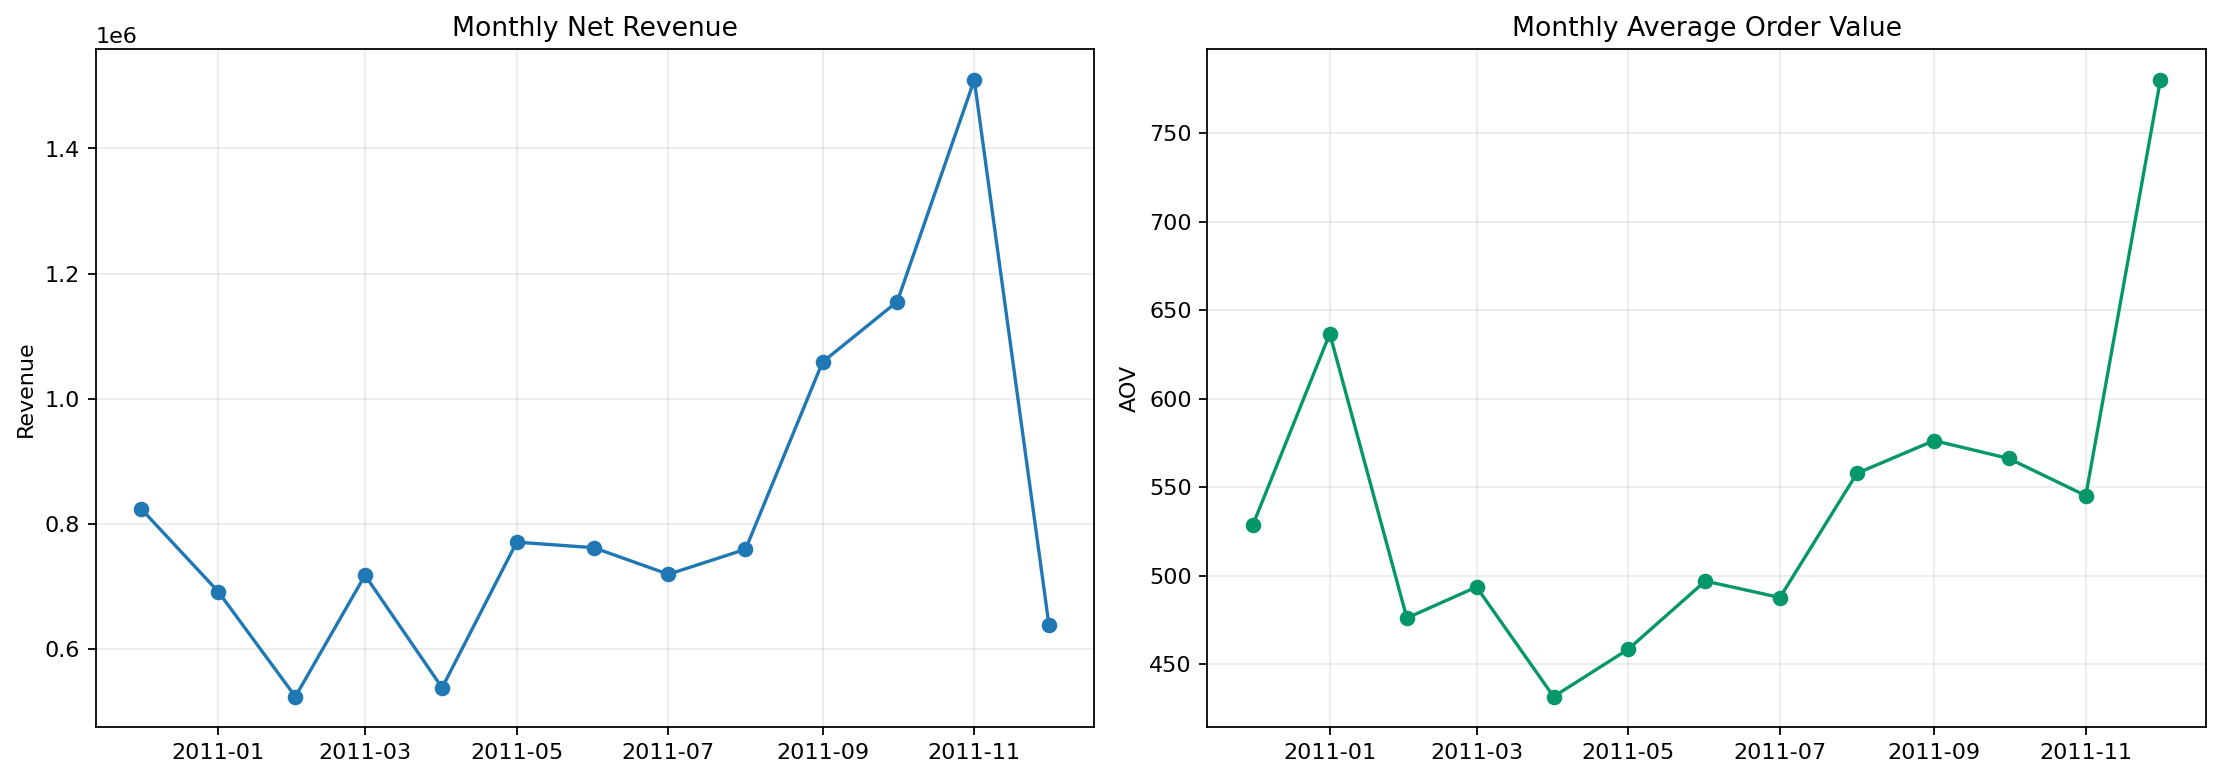

**Figure from key_visuals.ipynb, original code cell 4**

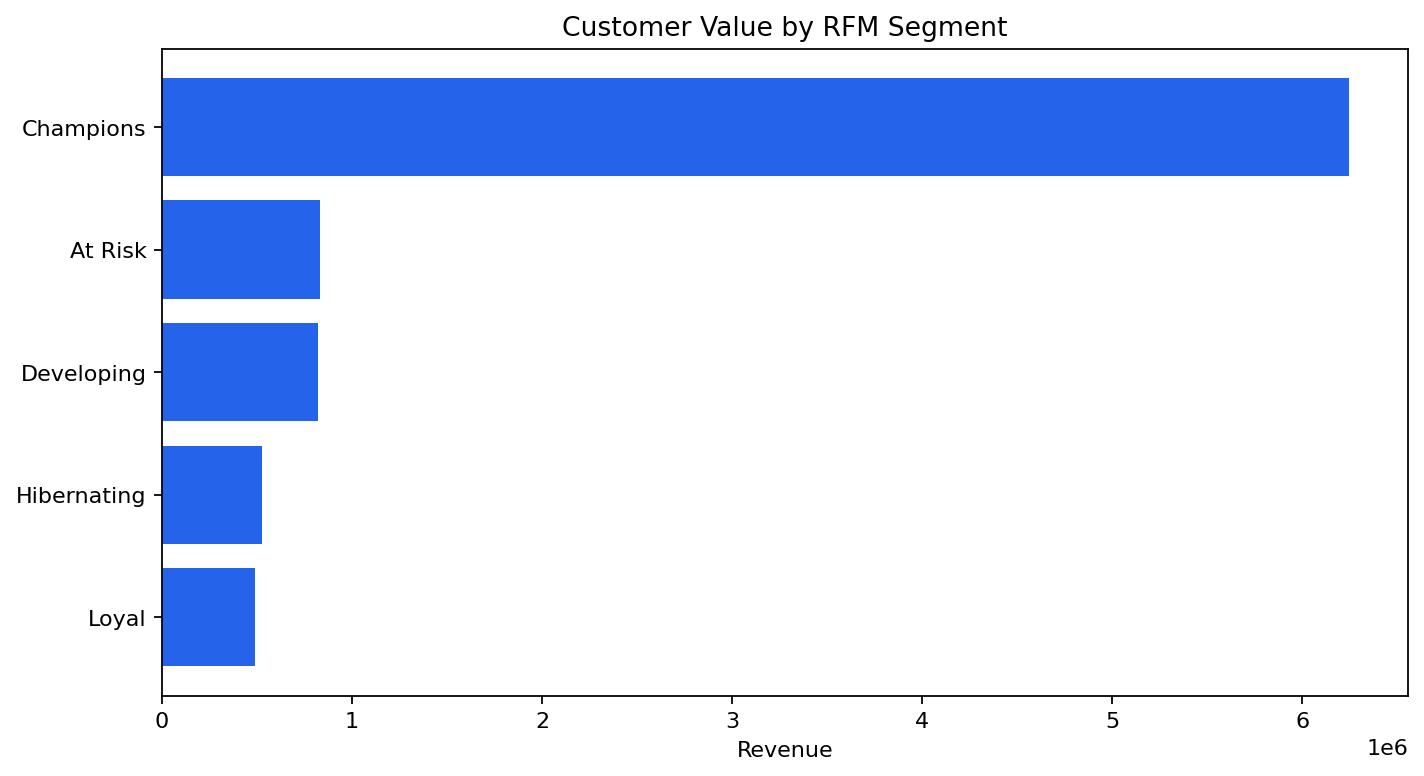

**Figure from key_visuals.ipynb, original code cell 5**

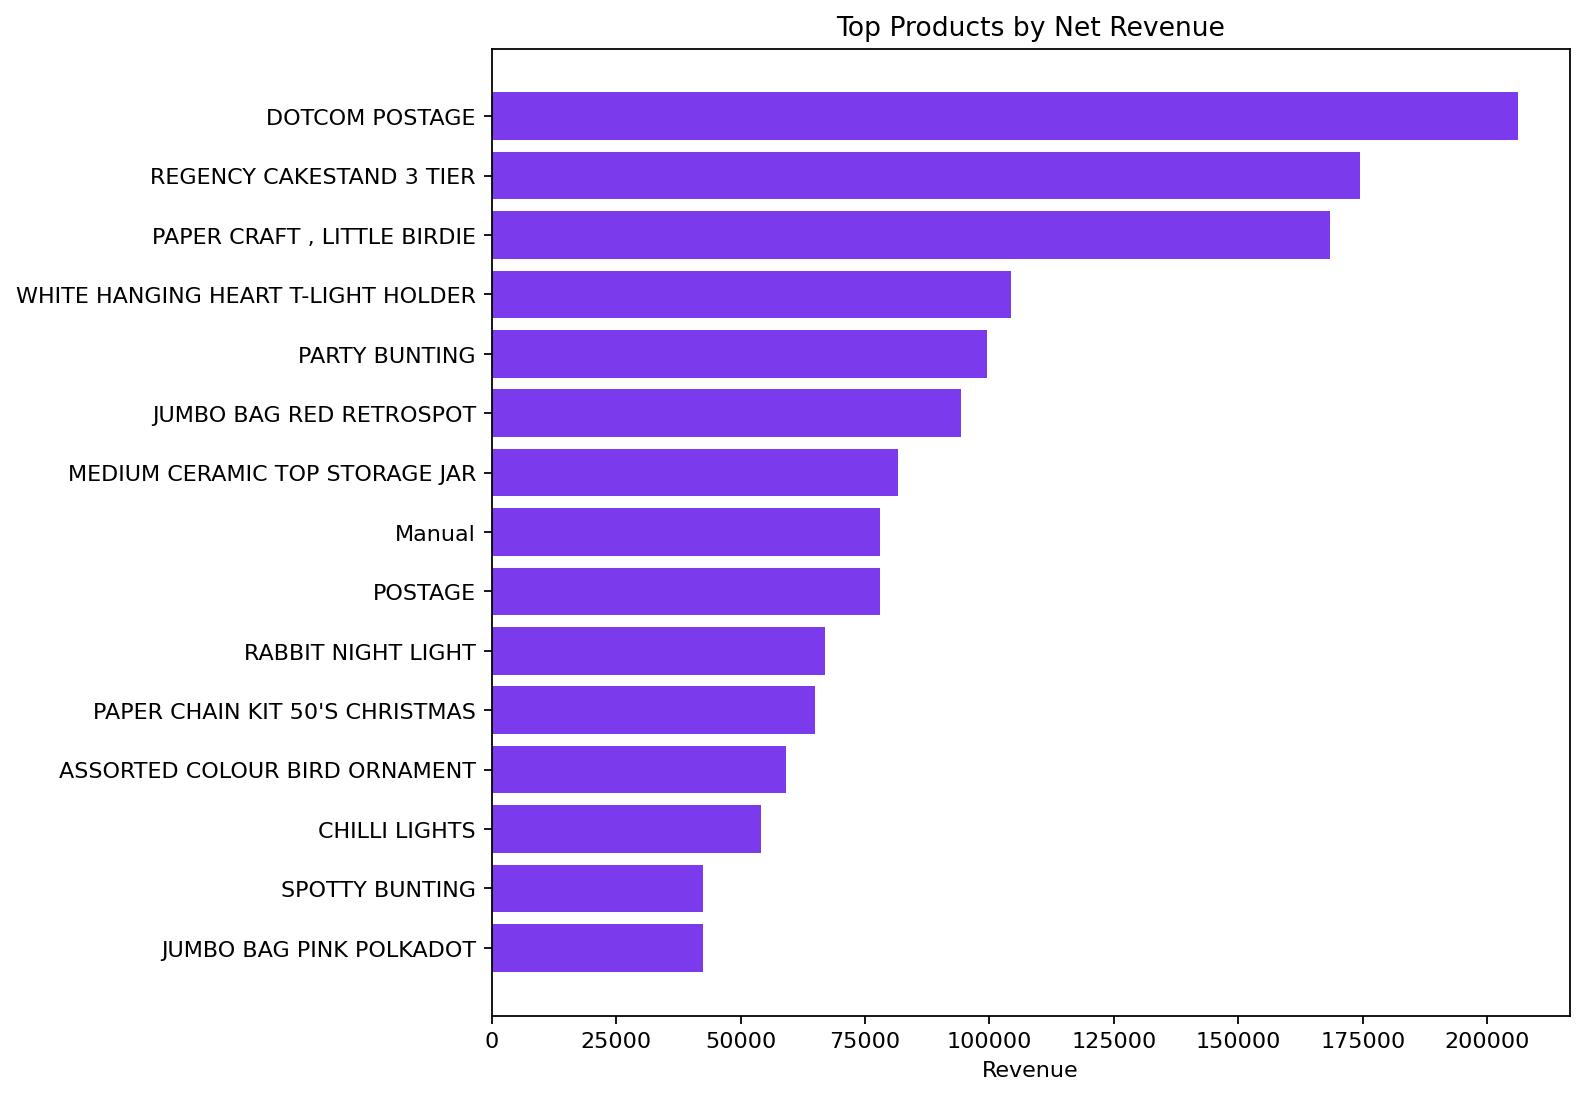